# Clasificación de especies sobre recortes (crops) de peces

1. Se recorta cada individuo (bbox del polígono YOLO-seg) de las imágenes de `dataset/` → `dataset_crops/{split}/{especie}/`.
2. Funciones comunes de **train/val** (loss, accuracy, mAP por época con barra de progreso + ETA) y de **test** (métricas completas, matriz de confusión opcional, complejidad y latencia).
3. Se entrenan 11 backbones livianos (torchvision / timm) con los mismos hiperparámetros y se comparan en una tabla.

Notas de diseño:
- Se respeta el split train/val/test original de `dataset/` (agrupado por `group`, sin fugas).
- Los recortes se redimensionan con **letterbox** (manteniendo aspecto + relleno a cuadrado): los peces son muy alargados y un resize directo a 224×224 los deforma.
- La normalización va **dentro del modelo** (`Normalized`), así cada backbone usa su propia mean/std (los `tf_efficientnet_lite*` usan 0.5/0.5, el resto ImageNet).
- mAP = media sobre especies de la *average precision* one-vs-rest (área bajo la curva precisión-recall).
- `num_workers=0` (Windows + notebook) → los recortes se precargan en RAM ya en letterbox para que no haya cuello de botella.

In [1]:
import json, time, copy, math, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.utils.flop_counter import FlopCounterMode
import torchvision.models as tvm
import torchvision.transforms as T
from torchvision.transforms import v2
import timm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, average_precision_score, confusion_matrix, cohen_kappa_score)

ROOT  = Path.cwd()
SRC   = ROOT / "dataset"          # imágenes + labels YOLO-seg (una línea = un individuo)
CROPS = ROOT / "dataset_crops"    # recortes generados
RUNS  = ROOT / "runs" / "cls"     # pesos, historiales y resultados por modelo
SPLITS  = ["train", "val", "test"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

PAD = 0.05                # margen alrededor de la bbox (fracción del ancho/alto de la caja)
SEED = 42
IMG_SIZE = 224
BATCH = 32
EPOCHS = 40
PATIENCE = 8              # early stopping sobre val mAP
LR = 3e-4
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
USE_CLASS_WEIGHTS = True  # compensa el desbalance (palometa ~3x boga/surubí)
FORCE_RETRAIN = False     # False: si un modelo ya tiene results.json se cargan sus resultados sin reentrenar

# AMP: el GradScaler saltea el primer optimizer.step() y PyTorch avisa que el scheduler "se adelantó" (inofensivo)
warnings.filterwarnings("ignore", message="Detected call of `lr_scheduler.step()`")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RUNS.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
print("Device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")

W1030 12:18:11.393000 22472 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Device: cuda (NVIDIA GeForce GTX 1650)


## 1. Recortes de cada individuo

Cada línea del label YOLO-seg es un individuo; su bbox es el min/max del polígono, ampliada un `PAD` por lado y recortada a los bordes de la imagen.
La especie sale del prefijo del nombre (`especie__id.jpg`) y el `group` de `split.csv`. Se guarda un índice en `dataset_crops/crops.csv`.
Si el índice ya existe y todos los recortes están en disco, la celda no hace nada.

In [2]:
INDEX_CSV = CROPS / "crops.csv"

def yolo_boxes(lbl_path, w, h):
    # bbox (x1, y1, x2, y2) en píxeles de cada individuo; acepta polígonos (seg) o cajas (cls cx cy bw bh)
    boxes = []
    for line in lbl_path.read_text().splitlines():
        vals = line.split()
        if len(vals) == 5:
            cx, cy, bw, bh = (float(v) for v in vals[1:])
            boxes.append(((cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h))
        elif len(vals) > 5:
            xy = np.array(vals[1:], dtype=float).reshape(-1, 2) * [w, h]
            boxes.append((*xy.min(0), *xy.max(0)))
    return boxes

def crops_ready():
    if not INDEX_CSV.exists():
        return False
    return all((CROPS / p).exists() for p in pd.read_csv(INDEX_CSV)["crop"])

if crops_ready():
    print(f"ya creado ({INDEX_CSV})")
else:
    groups = {r.file.replace("/", "__"): r.group for r in pd.read_csv(SRC / "split.csv").itertuples()}
    rows = []
    for split in SPLITS:
        imgs = sorted(p for p in (SRC / "images" / split).iterdir() if p.suffix.lower() in IMG_EXT)
        for img_path in tqdm(imgs, desc=f"Recortando {split}"):
            lbl = SRC / "labels" / split / (img_path.stem + ".txt")
            if not lbl.exists():
                continue
            species = img_path.stem.split("__")[0]
            img = ImageOps.exif_transpose(Image.open(img_path)).convert("RGB")
            W, H = img.size
            for k, (x1, y1, x2, y2) in enumerate(yolo_boxes(lbl, W, H)):
                px, py = PAD * (x2 - x1), PAD * (y2 - y1)
                box = (max(0, int(x1 - px)), max(0, int(y1 - py)), min(W, int(math.ceil(x2 + px))), min(H, int(math.ceil(y2 + py))))
                if box[2] - box[0] < 8 or box[3] - box[1] < 8:
                    continue
                rel = Path(split) / species / f"{img_path.stem}_{k}.jpg"
                (CROPS / rel).parent.mkdir(parents=True, exist_ok=True)
                img.crop(box).save(CROPS / rel, quality=95)
                rows.append(dict(crop=rel.as_posix(), split=split, species=species, source=img_path.name,
                                 group=groups.get(img_path.name, img_path.stem), individual=k,
                                 x1=box[0], y1=box[1], x2=box[2], y2=box[3]))
    pd.DataFrame(rows).to_csv(INDEX_CSV, index=False)
    print(f"{len(rows)} recortes creados en {CROPS}")

crops_df = pd.read_csv(INDEX_CSV)
pd.crosstab(crops_df.species, crops_df.split, margins=True)[SPLITS + ["All"]]

ya creado (c:\Users\juanm\Documents\GitHub\fish_cv_pfc\dataset_crops\crops.csv)


split,train,val,test,All
species,,,,
boga,79,16,32,127
dorado,131,29,28,188
palometa,250,54,53,357
sabalo,188,41,40,269
surubi_pintado,74,15,15,104
tararira,191,39,41,271
All,913,194,209,1316


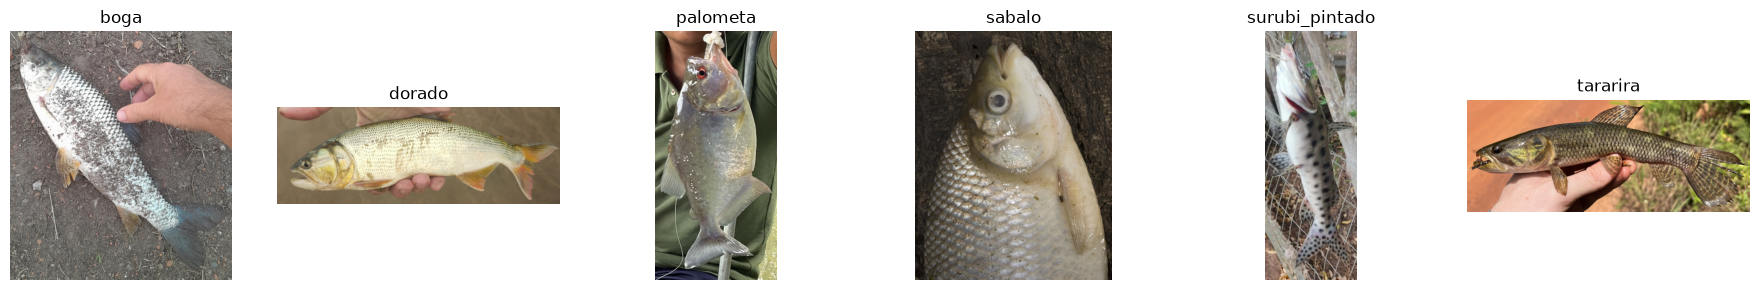

In [3]:
# Un recorte de ejemplo por especie
CLASSES = sorted(crops_df.species.unique())
fig, axes = plt.subplots(1, len(CLASSES), figsize=(3 * len(CLASSES), 3))
for ax, sp in zip(axes, CLASSES):
    p = crops_df[(crops_df.species == sp) & (crops_df.split == "train")].sample(1, random_state=SEED).crop.iloc[0]
    ax.imshow(Image.open(CROPS / p)); ax.set_title(sp); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Dataset y aumentación de datos

**Aumentaciones "seguras"** (siempre activas en train): no cambian rasgos que definan la especie.
- `RandomHorizontalFlip`: un pez mirando a izquierda o derecha es la misma especie.
- `RandomAffine` suave (±15°, ±5 % traslación, escala 0.9–1.1): fotos de pescadores con el pez levemente inclinado/descentrado.
- `ColorJitter` de brillo/contraste ±20 %: variaciones de iluminación sin tocar el tono.

**Propuestas** (desactivadas en `EXTRA_AUG`; activar las que no rompan ninguna clase):

| flag | qué hace | posible riesgo |
|---|---|---|
| `vertical_flip` | volteo vertical | vientre arriba: poco natural, pero la textura/forma se conserva |
| `rotate_90` | rotaciones de 90/180/270° | hay fotos con el pez colgado vertical; ayuda a eso, pero mezcla orientaciones |
| `random_resized_crop` | recorte aleatorio 60–100 % del área | puede dejar afuera la cola/cabeza (forma de aleta caudal, boca de tararira, barbillas del surubí) |
| `saturation_hue` | saturación ±30 %, tono ±0.05 | **dorado** se define mucho por el color dorado; la palometa tiene vientre rojizo |
| `grayscale` | 10 % de imágenes en gris | elimina el color: dorado vs sábalo (plateado) se vuelven más parecidos |
| `blur` | desenfoque gaussiano (p=0.2) | borra las manchas del **surubí pintado** y las escamas finas |
| `perspective` | distorsión de perspectiva (p=0.3) | cambia proporciones del cuerpo (palometa alta y corta vs boga alargada) |
| `random_erasing` | tapa un parche del pez (p=0.25) | puede borrar justo el rasgo distintivo; a cambio regulariza fuerte |
| `mixup_cutmix` | mezcla pares de imágenes/etiquetas por batch | regulariza mucho con pocos datos; entrena más lento |

Con la celda de vista previa podés ver cómo queda cada especie con **todas** las propuestas activadas.

In [4]:
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
PAD_COLOR = (124, 116, 104)   # ≈ media ImageNet: tras normalizar queda ≈ 0

def letterbox(img, size=IMG_SIZE):
    img = ImageOps.contain(img, (size, size), Image.BICUBIC)
    canvas = Image.new("RGB", (size, size), PAD_COLOR)
    canvas.paste(img, ((size - img.width) // 2, (size - img.height) // 2))
    return canvas

class CropDataset(Dataset):
    # Recortes precargados en RAM ya en letterbox; devuelve tensores en [0, 1] (la normalización la hace el modelo)
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.labels = self.df.species.map(CLS2IDX).to_numpy()
        self.images = [letterbox(Image.open(CROPS / p).convert("RGB")) for p in tqdm(self.df.crop, desc="Cargando", leave=False)]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return self.transform(self.images[i]), self.labels[i]

SAFE_AUG = [
    T.RandomHorizontalFlip(0.5),
    T.RandomAffine(degrees=15, translate=(0.05, 0.05), scale=(0.9, 1.1), fill=PAD_COLOR),
    T.ColorJitter(brightness=0.2, contrast=0.2),
]
EXTRA_AUG = dict(
    vertical_flip=True,
    rotate_90=True,
    random_resized_crop=True,
    saturation_hue=False,
    grayscale=False,
    blur=False,
    perspective=True,
    random_erasing=True,
    mixup_cutmix=False,   # se aplica por batch dentro de train_model
)

def build_train_transform(extra=EXTRA_AUG):
    t = list(SAFE_AUG)
    if extra["random_resized_crop"]:
        t.insert(0, T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.75, 1.33)))
    if extra["vertical_flip"]:
        t.append(T.RandomVerticalFlip(0.5))
    if extra["rotate_90"]:
        t.append(T.RandomChoice([T.RandomRotation((a, a), fill=PAD_COLOR) for a in (0, 90, 180, 270)]))
    if extra["perspective"]:
        t.append(T.RandomPerspective(0.2, p=0.3, fill=PAD_COLOR))
    if extra["saturation_hue"]:
        t.append(T.ColorJitter(saturation=0.3, hue=0.05))
    if extra["grayscale"]:
        t.append(T.RandomGrayscale(0.1))
    if extra["blur"]:
        t.append(T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2))
    t.append(T.ToTensor())
    if extra["random_erasing"]:
        t.append(T.RandomErasing(p=0.25, scale=(0.02, 0.15), value="random"))
    return T.Compose(t)

EVAL_TF = T.ToTensor()

train_ds = CropDataset(crops_df[crops_df.split == "train"], build_train_transform())
val_ds   = CropDataset(crops_df[crops_df.split == "val"], EVAL_TF)
test_ds  = CropDataset(crops_df[crops_df.split == "test"], EVAL_TF)

def make_loaders(batch=BATCH):
    pin = DEVICE.type == "cuda"
    return (DataLoader(train_ds, batch, shuffle=True, num_workers=0, pin_memory=pin, drop_last=True),
            DataLoader(val_ds, batch, shuffle=False, num_workers=0, pin_memory=pin),
            DataLoader(test_ds, batch, shuffle=False, num_workers=0, pin_memory=pin))

counts = np.bincount(train_ds.labels, minlength=NUM_CLASSES)
CLASS_WEIGHTS = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32)
print(f"train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")
pd.DataFrame({"n_train": counts, "peso_loss": CLASS_WEIGHTS.numpy().round(2)}, index=CLASSES)

Cargando:   0%|          | 0/913 [00:00<?, ?it/s]

Cargando:   0%|          | 0/194 [00:00<?, ?it/s]

Cargando:   0%|          | 0/209 [00:00<?, ?it/s]

train=913  val=194  test=209


,n_train,peso_loss
boga,79,1.93
dorado,131,1.16
palometa,250,0.61
sabalo,188,0.81
surubi_pintado,74,2.06
tararira,191,0.80


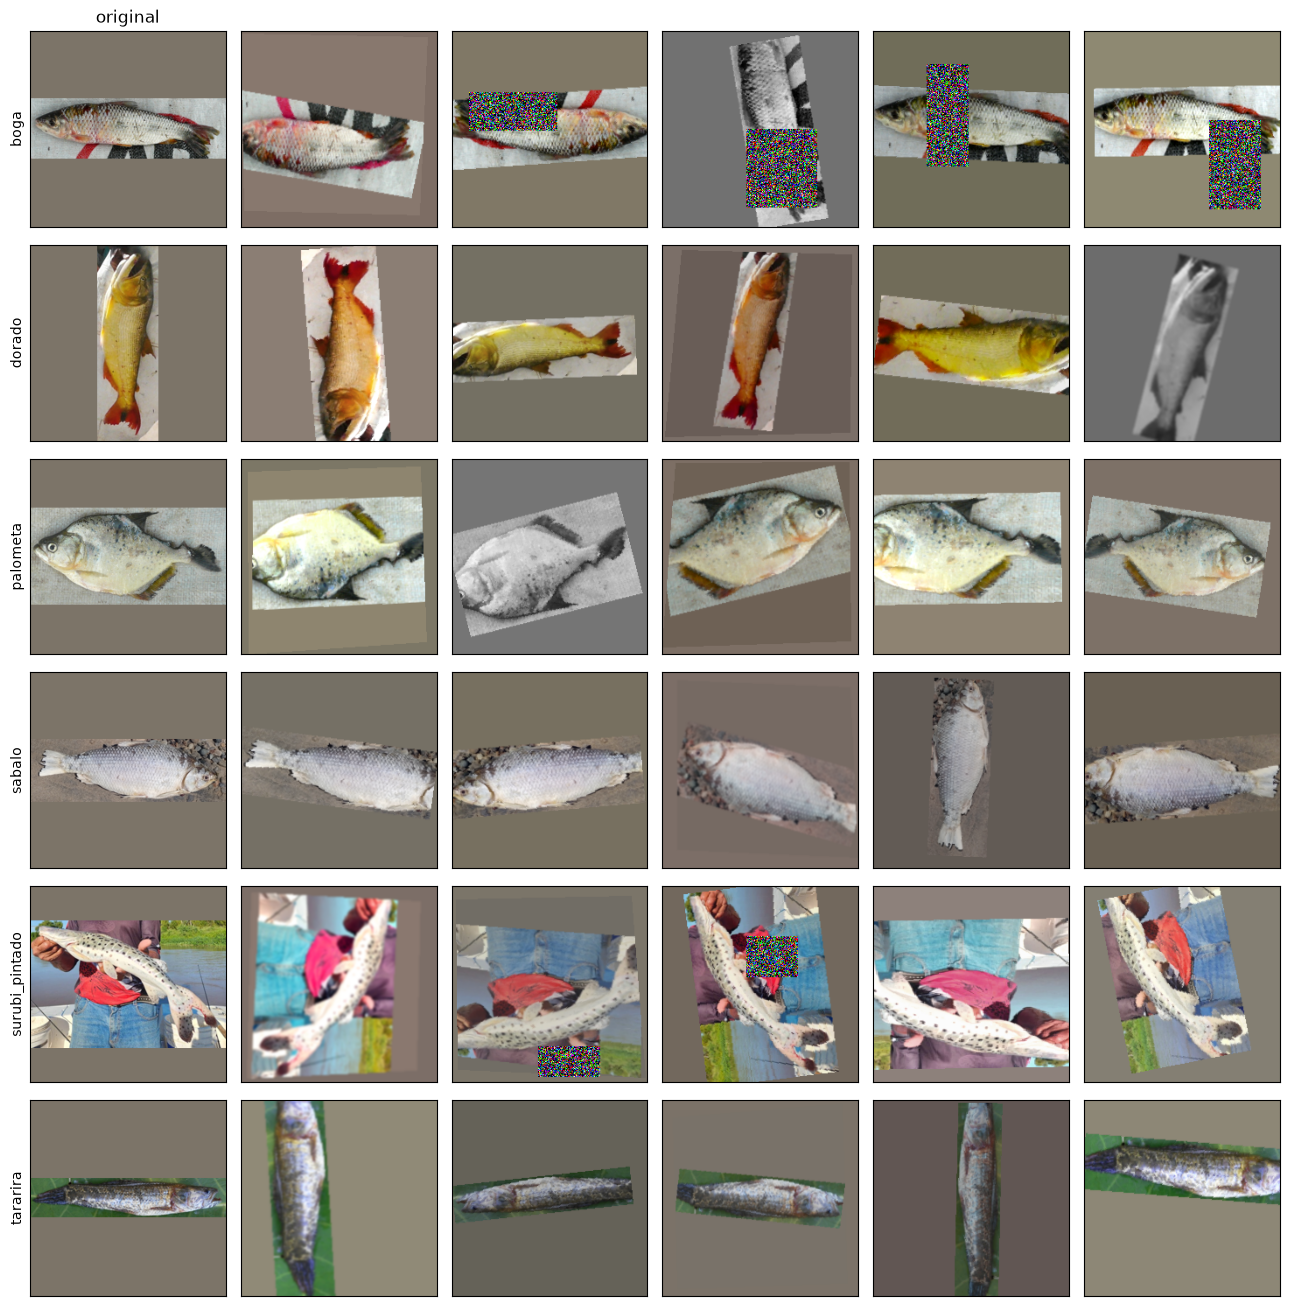

In [5]:
# Vista previa: original + 5 versiones aumentadas por especie.
# PREVIEW_EXTRA = EXTRA_AUG -> lo que se usa en el entrenamiento; con todo en True se ven todas las propuestas.
PREVIEW_EXTRA = {k: True for k in EXTRA_AUG}
tf = build_train_transform(PREVIEW_EXTRA)
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(13, 2.2 * NUM_CLASSES))
for r, sp in enumerate(CLASSES):
    img = train_ds.images[int(np.where(train_ds.labels == r)[0][0])]
    axes[r, 0].imshow(img); axes[r, 0].set_ylabel(sp)
    for c in range(1, 6):
        axes[r, c].imshow(tf(img).permute(1, 2, 0).clamp(0, 1))
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title("original")
plt.tight_layout(); plt.show()

## 3. Funciones: modelos, train/val y test

- `train_model(...)`: AdamW + warmup de 1 época + coseno, AMP, CrossEntropy (con pesos por clase y label smoothing), early stopping sobre **val mAP**.
  Imprime la cantidad de parámetros, una barra por época (con el tiempo restante de la época) y al terminar cada época la loss/mAP de train y val + ETA del entrenamiento. Restaura y guarda los mejores pesos.
- `test_model(...)`: loss, accuracy, balanced accuracy, precisión/recall/F1 macro, F1 ponderado, mAP, top-2, kappa, métricas por especie, GFLOPs, tamaño, latencia (batch=1, GPU y CPU) y throughput. Con `matrix_conf=True` dibuja la matriz de confusión.
- `run_experiment(name)`: arma el modelo, entrena, testea y guarda todo en `runs/cls/<name>/`. Si ya existe y `FORCE_RETRAIN=False`, carga los resultados.

In [6]:
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class Normalized(nn.Module):
    # Normaliza dentro del modelo para que cada backbone use su propia mean/std
    def __init__(self, backbone, mean, std):
        super().__init__()
        self.backbone = backbone
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))

    def forward(self, x):
        return self.backbone((x - self.mean) / self.std)

def tv_model(arch, num_classes=None):
    m = tvm.get_model(arch, weights="DEFAULT")
    num_classes = num_classes or NUM_CLASSES
    if hasattr(m, "fc"):    # resnet, shufflenet
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    else:                   # mobilenet_v3, efficientnet, convnext: último Linear del classifier
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    return Normalized(m, IMAGENET_MEAN, IMAGENET_STD)

def timm_model(arch, num_classes=None):
    m = timm.create_model(arch, pretrained=True, num_classes=num_classes or NUM_CLASSES)
    return Normalized(m, m.pretrained_cfg["mean"], m.pretrained_cfg["std"])

# nombre -> (librería, constructor)
MODELS = {
    "mobilenet_v3_small": ("torchvision", lambda: tv_model("mobilenet_v3_small")),
    "mobilenet_v3_large": ("torchvision", lambda: tv_model("mobilenet_v3_large")),
    "efficientnet_lite0": ("timm",        lambda: timm_model("tf_efficientnet_lite0.in1k")),
    "efficientnet_lite1": ("timm",        lambda: timm_model("tf_efficientnet_lite1.in1k")),
    "efficientnet_b0":    ("torchvision", lambda: tv_model("efficientnet_b0")),
    "convnext_pico":      ("timm",        lambda: timm_model("convnext_pico.d1_in1k")),
    "convnext_nano":      ("timm",        lambda: timm_model("convnext_nano.in12k_ft_in1k")),
    "convnext_tiny":      ("torchvision", lambda: tv_model("convnext_tiny")),
    "shufflenet_v2_x0_5": ("torchvision", lambda: tv_model("shufflenet_v2_x0_5")),
    "shufflenet_v2_x1_0": ("torchvision", lambda: tv_model("shufflenet_v2_x1_0")),
    "resnet18":           ("torchvision", lambda: tv_model("resnet18")),
}

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def model_complexity(model):
    # GFLOPs (1 imagen) y tamaño en MB de los pesos fp32
    m = copy.deepcopy(model).cpu().eval()
    try:
        with FlopCounterMode(display=False) as fc, torch.no_grad():
            m(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE))
        gflops = fc.get_total_flops() / 1e9
    except Exception:
        gflops = float("nan")
    size_mb = sum(t.numel() * t.element_size() for t in list(m.parameters()) + list(m.buffers())) / 1e6
    return gflops, size_mb

@torch.inference_mode()
def measure_latency(model, device, batch=1, warmup=10, runs=50):
    # ms por imagen con el batch dado
    m = copy.deepcopy(model).to(device).eval() if device != next(model.parameters()).device else model.eval()
    x = torch.rand(batch, 3, IMG_SIZE, IMG_SIZE, device=device)
    for _ in range(warmup):
        m(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        m(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / (runs * batch) * 1000

def classification_metrics(y, probs):
    pred = probs.argmax(1)
    onehot = np.eye(NUM_CLASSES)[y]
    return dict(acc=accuracy_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred),
                f1_macro=f1_score(y, pred, average="macro", zero_division=0),
                mAP=average_precision_score(onehot, probs, average="macro"))

def make_criterion():
    return nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE) if USE_CLASS_WEIGHTS else None,
                               label_smoothing=LABEL_SMOOTHING)

@torch.inference_mode()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, probs, ys = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(x)
        loss_sum += criterion(logits.float(), y).item() * len(y)
        probs.append(logits.float().softmax(1).cpu()); ys.append(y.cpu())
    y, probs = torch.cat(ys).numpy(), torch.cat(probs).numpy()
    return dict(loss=loss_sum / len(y), **classification_metrics(y, probs), y=y, probs=probs)

In [7]:
def train_model(model, train_loader, val_loader, name, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY,
                patience=PATIENCE, mixup_cutmix=EXTRA_AUG["mixup_cutmix"]):
    model = model.to(DEVICE)
    total, trainable = count_params(model)
    print(f"{name}: {total / 1e6:.2f} M parámetros ({trainable / 1e6:.2f} M entrenables)")

    criterion = make_criterion()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps, warm = epochs * len(train_loader), len(train_loader)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    mixer = v2.RandomChoice([v2.MixUp(alpha=0.2, num_classes=NUM_CLASSES),
                             v2.CutMix(alpha=1.0, num_classes=NUM_CLASSES)]) if mixup_cutmix else None

    history, best_map, best_state, best_epoch, bad = [], -1.0, None, 0, 0
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        t_ep = time.time()
        loss_sum, n, probs, ys = 0.0, 0, [], []
        pbar = tqdm(train_loader, desc=f"[{name}] época {epoch}/{epochs}", leave=False)
        for x, y in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            target = y
            if mixer is not None:
                x, target = mixer(x, y)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(x)
                loss = criterion(logits.float(), target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            loss_sum += loss.item() * len(y); n += len(y)
            probs.append(logits.detach().float().softmax(1).cpu()); ys.append(y.cpu())
            pbar.set_postfix(loss=f"{loss_sum / n:.4f}")

        tr = classification_metrics(torch.cat(ys).numpy(), torch.cat(probs).numpy())
        va = evaluate(model, val_loader, criterion)
        ep_time = time.time() - t_ep
        history.append(dict(epoch=epoch, lr=optimizer.param_groups[0]["lr"], time_s=ep_time,
                            train_loss=loss_sum / n, train_acc=tr["acc"], train_mAP=tr["mAP"],
                            val_loss=va["loss"], val_acc=va["acc"], val_f1_macro=va["f1_macro"], val_mAP=va["mAP"]))

        improved = va["mAP"] > best_map
        if improved:
            best_map, best_epoch, bad = va["mAP"], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        eta = (time.time() - t_start) / epoch * (epochs - epoch)
        print(f"[{name}] época {epoch:>2}/{epochs} | train loss {loss_sum / n:.4f} mAP {tr['mAP']:.4f} | "
              f"val loss {va['loss']:.4f} mAP {va['mAP']:.4f} acc {va['acc']:.4f} | {ep_time:.1f}s"
              f" | ETA máx {eta / 60:.1f} min" + ("  *mejor*" if improved else ""))
        if bad >= patience:
            print(f"[{name}] early stopping: {patience} épocas sin mejorar val mAP")
            break

    train_time = time.time() - t_start
    model.load_state_dict(best_state)
    hist = pd.DataFrame(history)
    best = hist.loc[hist.epoch == best_epoch].iloc[0]
    info = dict(params_M=total / 1e6, trainable_params_M=trainable / 1e6, epochs_run=len(hist), best_epoch=best_epoch,
                train_time_min=train_time / 60, sec_per_epoch=hist.time_s.mean(),
                peak_gpu_mem_GB=torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else float("nan"),
                train_loss=best.train_loss, train_mAP=best.train_mAP,
                val_loss=best.val_loss, val_acc=best.val_acc, val_mAP=best.val_mAP)
    print(f"[{name}] fin: {train_time / 60:.1f} min, mejor época {best_epoch} (val mAP {best_map:.4f})")
    return model, hist, info

In [8]:
def plot_confusion(cm, title=""):
    cm_norm = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    for ax, mat, ttl, fmt in [(axes[0], cm, "conteos", "d"), (axes[1], cm_norm, "normalizada por fila (recall)", ".2f")]:
        ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center", fontsize=9,
                        color="white" if cm_norm[i, j] > 0.5 else "black")
        ax.set_xticks(range(NUM_CLASSES), CLASSES, rotation=45, ha="right")
        ax.set_yticks(range(NUM_CLASSES), CLASSES)
        ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title(f"{title} — {ttl}")
    plt.tight_layout(); plt.show()

def test_model(model, loader, name="", matrix_conf=False, measure_speed=True):
    model = model.to(DEVICE)
    res = evaluate(model, loader, make_criterion())
    y, probs = res["y"], res["probs"]
    pred = probs.argmax(1)
    onehot = np.eye(NUM_CLASSES)[y]

    prec, rec, f1, sup = precision_recall_fscore_support(y, pred, labels=range(NUM_CLASSES), zero_division=0)
    ap = average_precision_score(onehot, probs, average=None)
    per_class = pd.DataFrame(dict(precision=prec, recall=rec, f1=f1, AP=ap, support=sup), index=CLASSES)
    top2 = np.mean([yi in np.argsort(pi)[-2:] for yi, pi in zip(y, probs)])
    metrics = dict(test_loss=res["loss"], test_acc=res["acc"], test_balanced_acc=res["balanced_acc"],
                   test_precision_macro=prec.mean(), test_recall_macro=rec.mean(), test_f1_macro=f1.mean(),
                   test_f1_weighted=f1_score(y, pred, average="weighted", zero_division=0),
                   test_mAP=res["mAP"], test_top2_acc=top2, test_kappa=cohen_kappa_score(y, pred),
                   worst_class=per_class.f1.idxmin(), worst_class_f1=per_class.f1.min())

    if measure_speed:
        gflops, size_mb = model_complexity(model)
        metrics.update(GFLOPs=gflops, size_MB=size_mb,
                       latency_gpu_ms=measure_latency(model, DEVICE) if DEVICE.type == "cuda" else float("nan"),
                       throughput_gpu_img_s=1000 / measure_latency(model, DEVICE, batch=BATCH, runs=20) if DEVICE.type == "cuda" else float("nan"),
                       latency_cpu_ms=measure_latency(model, torch.device("cpu"), warmup=5, runs=30))

    print(f"[{name}] TEST  " + "  ".join(f"{k}={v:.4f}" for k, v in metrics.items() if isinstance(v, float) and k.startswith("test_")))
    if measure_speed:
        print(f"[{name}] {metrics['GFLOPs']:.2f} GFLOPs | {metrics['size_MB']:.1f} MB | "
              f"GPU {metrics['latency_gpu_ms']:.2f} ms/img ({metrics['throughput_gpu_img_s']:.0f} img/s @bs{BATCH}) | "
              f"CPU {metrics['latency_cpu_ms']:.1f} ms/img")
    display(per_class.round(3))

    cm = confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    if matrix_conf:
        plot_confusion(cm, name)
    preds = pd.DataFrame(dict(crop=loader.dataset.df.crop, y_true=[CLASSES[i] for i in y],
                              y_pred=[CLASSES[i] for i in pred], conf=probs.max(1)))
    preds[[f"p_{c}" for c in CLASSES]] = probs
    return dict(metrics=metrics, per_class=per_class, confusion=cm, preds=preds)

In [9]:
ALL_RESULTS = {}

def run_experiment(name, matrix_conf=True, batch=BATCH):
    lib, builder = MODELS[name]
    out = RUNS / name
    if (out / "results.json").exists() and not FORCE_RETRAIN:
        print(f"{name}: ya entrenado -> cargando {out}")
        r = dict(summary=json.loads((out / "results.json").read_text()),
                 history=pd.read_csv(out / "history.csv"),
                 per_class=pd.read_csv(out / "per_class.csv", index_col=0),
                 confusion=np.load(out / "confusion.npy"),
                 preds=pd.read_csv(out / "test_preds.csv"))
        display(r["per_class"].round(3))
        if matrix_conf:
            plot_confusion(r["confusion"], name)
    else:
        seed_everything()
        out.mkdir(parents=True, exist_ok=True)
        train_loader, val_loader, test_loader = make_loaders(batch)
        model = builder()
        model, hist, info = train_model(model, train_loader, val_loader, name)
        test = test_model(model, test_loader, name, matrix_conf=matrix_conf)
        summary = dict(model=name, library=lib, batch=batch, **info, **test["metrics"])
        torch.save(model.state_dict(), out / "best.pt")
        (out / "results.json").write_text(json.dumps(summary, indent=2, default=float))
        hist.to_csv(out / "history.csv", index=False)
        test["per_class"].to_csv(out / "per_class.csv")
        np.save(out / "confusion.npy", test["confusion"])
        test["preds"].to_csv(out / "test_preds.csv", index=False)
        r = dict(summary=summary, history=hist, **{k: test[k] for k in ("per_class", "confusion", "preds")})
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    ALL_RESULTS[name] = r
    return r

## 4. Modelos

Todos con pesos ImageNet, entrada 224×224 y los mismos hiperparámetros. Cada celda entrena (o carga si ya está entrenado) y testea.

### MobileNetV3 Small (torchvision)

mobilenet_v3_small: 1.52 M parámetros (1.52 M entrenables)


[mobilenet_v3_small] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

[mobilenet_v3_small] época  1/40 | train loss 1.7634 mAP 0.3007 | val loss 1.4534 mAP 0.6460 acc 0.6031 | 5.0s | ETA máx 3.2 min  *mejor*


[mobilenet_v3_small] época 2/40:   0%|          | 0/28 [00:00<?, ?it/s]

[mobilenet_v3_small] época  2/40 | train loss 1.2482 mAP 0.6799 | val loss 1.2332 mAP 0.8164 acc 0.7165 | 4.7s | ETA máx 3.1 min  *mejor*


...

[mobilenet_v3_small] época 13/40:   0%|          | 0/28 [00:00<?, ?it/s]

[mobilenet_v3_small] época 13/40 | train loss 0.6466 mAP 0.9868 | val loss 0.7783 mAP 0.9603 acc 0.9227 | 5.1s | ETA máx 2.3 min


[mobilenet_v3_small] época 14/40:   0%|          | 0/28 [00:00<?, ?it/s]

[mobilenet_v3_small] época 14/40 | train loss 0.6288 mAP 0.9904 | val loss 0.7198 mAP 0.9815 acc 0.9485 | 5.1s | ETA máx 2.2 min
[mobilenet_v3_small] early stopping: 8 épocas sin mejorar val mAP
[mobilenet_v3_small] fin: 1.2 min, mejor época 6 (val mAP 0.9859)
[mobilenet_v3_small] TEST  test_loss=0.8775  test_acc=0.8469  test_balanced_acc=0.8231  test_precision_macro=0.8194  test_recall_macro=0.8231  test_f1_macro=0.8175  test_f1_weighted=0.8472  test_mAP=0.9025  test_top2_acc=0.9569  test_kappa=0.8121
[mobilenet_v3_small] 0.11 GFLOPs | 6.1 MB | GPU 7.99 ms/img (2436 img/s @bs32) | CPU 8.7 ms/img


,precision,recall,f1,AP,support
boga,0.920,0.719,0.807,0.884,32
dorado,0.750,0.857,0.800,0.897,28
palometa,0.964,1.000,0.981,0.994,53
sabalo,0.842,0.800,0.821,0.915,40
surubi_pintado,0.611,0.733,0.667,0.817,15
tararira,0.829,0.829,0.829,0.909,41


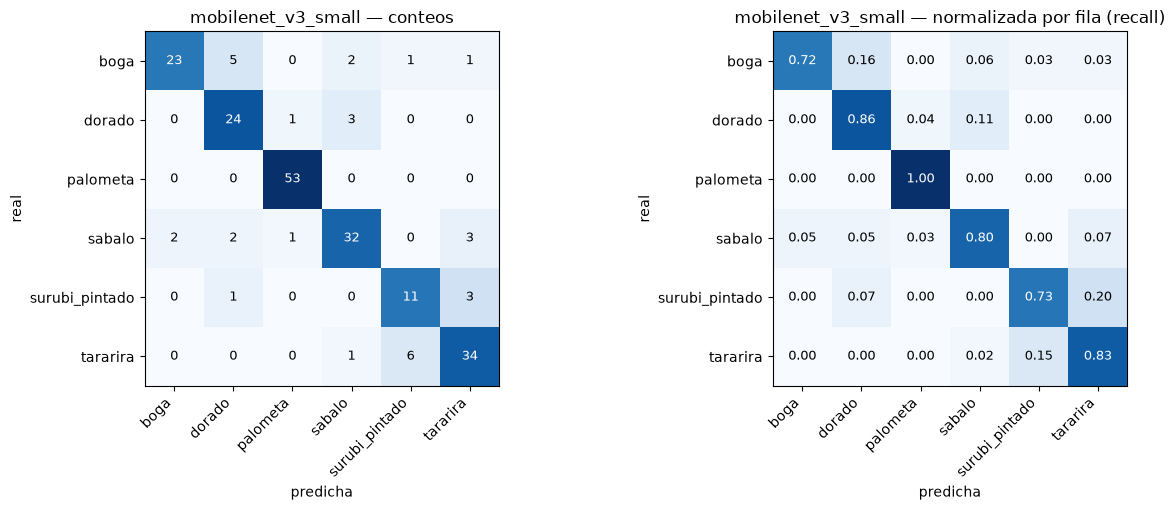

In [11]:
_ = run_experiment("mobilenet_v3_small")

### MobileNetV3 Large (torchvision)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\juanm/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:01<00:00, 14.0MB/s]


mobilenet_v3_large: 4.21 M parámetros (4.21 M entrenables)


[mobilenet_v3_large] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

[mobilenet_v3_large] época  1/40 | train loss 1.6909 mAP 0.4245 | val loss 1.2686 mAP 0.8451 acc 0.6237 | 13.1s | ETA máx 8.5 min  *mejor*


...

[mobilenet_v3_large] época 21/40:   0%|          | 0/28 [00:00<?, ?it/s]

[mobilenet_v3_large] época 21/40 | train loss 0.5296 mAP 0.9989 | val loss 0.6447 mAP 0.9885 acc 0.9588 | 8.4s | ETA máx 2.7 min


[mobilenet_v3_large] época 22/40:   0%|          | 0/28 [00:00<?, ?it/s]

[mobilenet_v3_large] época 22/40 | train loss 0.5240 mAP 0.9999 | val loss 0.6325 mAP 0.9856 acc 0.9588 | 8.3s | ETA máx 2.6 min
[mobilenet_v3_large] early stopping: 8 épocas sin mejorar val mAP
[mobilenet_v3_large] fin: 3.1 min, mejor época 14 (val mAP 0.9932)
[mobilenet_v3_large] TEST  test_loss=0.6937  test_acc=0.9426  test_balanced_acc=0.9295  test_precision_macro=0.9419  test_recall_macro=0.9295  test_f1_macro=0.9350  test_f1_weighted=0.9427  test_mAP=0.9697  test_top2_acc=0.9952  test_kappa=0.9293
[mobilenet_v3_large] 0.43 GFLOPs | 16.9 MB | GPU 8.85 ms/img (873 img/s @bs32) | CPU 15.3 ms/img


,precision,recall,f1,AP,support
boga,0.935,0.906,0.921,0.971,32
dorado,1.000,0.929,0.963,0.984,28
palometa,1.000,1.000,1.000,1.000,53
sabalo,0.878,0.900,0.889,0.965,40
surubi_pintado,0.929,0.867,0.897,0.923,15
tararira,0.909,0.976,0.941,0.976,41


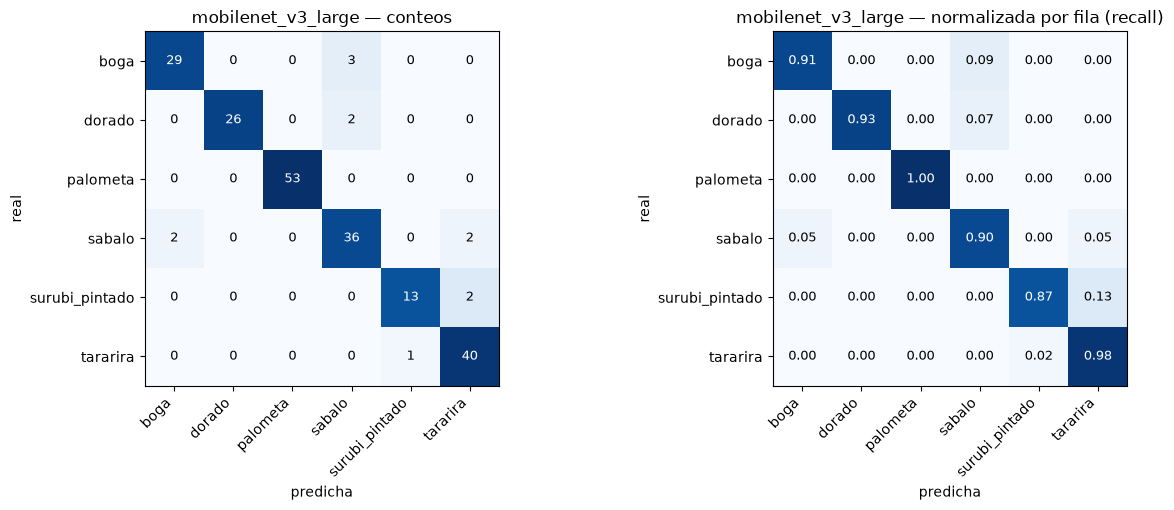

In [12]:
_ = run_experiment("mobilenet_v3_large")

### EfficientNet Lite0 (timm, `tf_efficientnet_lite0`)

c:\Users\juanm\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\juanm\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B / 18.8MB            

model.safetensors: downloading bytes:           |  0.00B            

efficientnet_lite0: 3.38 M parámetros (3.38 M entrenables)


c:\Users\juanm\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\juanm\.cache\huggingface\hub\models--timm--tf_efficientnet_lite0.in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


...

[efficientnet_lite0] época 24/40:   0%|          | 0/28 [00:00<?, ?it/s]

[efficientnet_lite0] época 24/40 | train loss 0.6312 mAP 0.9938 | val loss 0.7886 mAP 0.9643 acc 0.9175 | 10.6s | ETA máx 2.9 min


[efficientnet_lite0] época 25/40:   0%|          | 0/28 [00:00<?, ?it/s]

[efficientnet_lite0] época 25/40 | train loss 0.6438 mAP 0.9878 | val loss 0.7858 mAP 0.9574 acc 0.9381 | 10.6s | ETA máx 2.7 min
[efficientnet_lite0] early stopping: 8 épocas sin mejorar val mAP
[efficientnet_lite0] fin: 4.5 min, mejor época 17 (val mAP 0.9658)
[efficientnet_lite0] TEST  test_loss=0.7889  test_acc=0.9139  test_balanced_acc=0.9118  test_precision_macro=0.8917  test_recall_macro=0.9118  test_f1_macro=0.8981  test_f1_weighted=0.9157  test_mAP=0.9577  test_top2_acc=0.9617  test_kappa=0.8947
[efficientnet_lite0] 0.77 GFLOPs | 13.7 MB | GPU 9.74 ms/img (525 img/s @bs32) | CPU 18.5 ms/img


,precision,recall,f1,AP,support
boga,0.968,0.938,0.952,0.932,32
dorado,0.848,1.000,0.918,0.989,28
palometa,1.000,0.962,0.981,0.998,53
sabalo,1.000,0.875,0.933,0.983,40
surubi_pintado,0.684,0.867,0.765,0.907,15
tararira,0.850,0.829,0.840,0.938,41


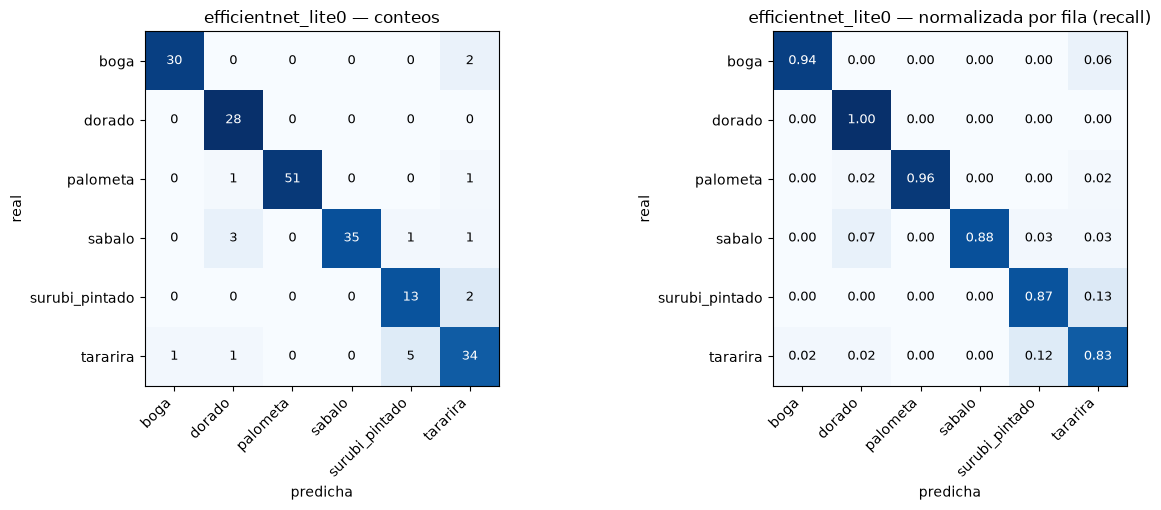

In [13]:
_ = run_experiment("efficientnet_lite0")

### EfficientNet Lite1 (timm, `tf_efficientnet_lite1`)

efficientnet_lite1: 4.14 M parámetros (4.14 M entrenables)


[efficientnet_lite1] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

C:\Users\juanm\AppData\Local\Temp\ipykernel_22472\1821984388.py:37: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[efficientnet_lite1] época  1/40 | train loss 3.2011 mAP 0.3010 | val loss 1.8373 mAP 0.6442 acc 0.5722 | 13.1s | ETA máx 8.5 min  *mejor*


[efficientnet_lite1] época 2/40:   0%|          | 0/28 [00:00<?, ?it/s]

...

[efficientnet_lite1] época 24/40:   0%|          | 0/28 [00:00<?, ?it/s]

[efficientnet_lite1] época 24/40 | train loss 0.6069 mAP 0.9947 | val loss 0.7651 mAP 0.9454 acc 0.9485 | 13.0s | ETA máx 3.5 min


[efficientnet_lite1] época 25/40:   0%|          | 0/28 [00:00<?, ?it/s]

[efficientnet_lite1] época 25/40 | train loss 0.6172 mAP 0.9955 | val loss 0.7555 mAP 0.9499 acc 0.9485 | 13.1s | ETA máx 3.3 min
[efficientnet_lite1] early stopping: 8 épocas sin mejorar val mAP
[efficientnet_lite1] fin: 5.4 min, mejor época 17 (val mAP 0.9599)
[efficientnet_lite1] TEST  test_loss=0.8318  test_acc=0.8804  test_balanced_acc=0.8643  test_precision_macro=0.8686  test_recall_macro=0.8643  test_f1_macro=0.8646  test_f1_weighted=0.8810  test_mAP=0.9413  test_top2_acc=0.9617  test_kappa=0.8533
[efficientnet_lite1] 1.00 GFLOPs | 16.8 MB | GPU 9.92 ms/img (408 img/s @bs32) | CPU 21.8 ms/img


,precision,recall,f1,AP,support
boga,0.833,0.938,0.882,0.963,32
dorado,0.800,0.857,0.828,0.925,28
palometa,1.000,0.906,0.950,0.987,53
sabalo,0.872,0.850,0.861,0.963,40
surubi_pintado,0.846,0.733,0.786,0.873,15
tararira,0.860,0.902,0.881,0.936,41


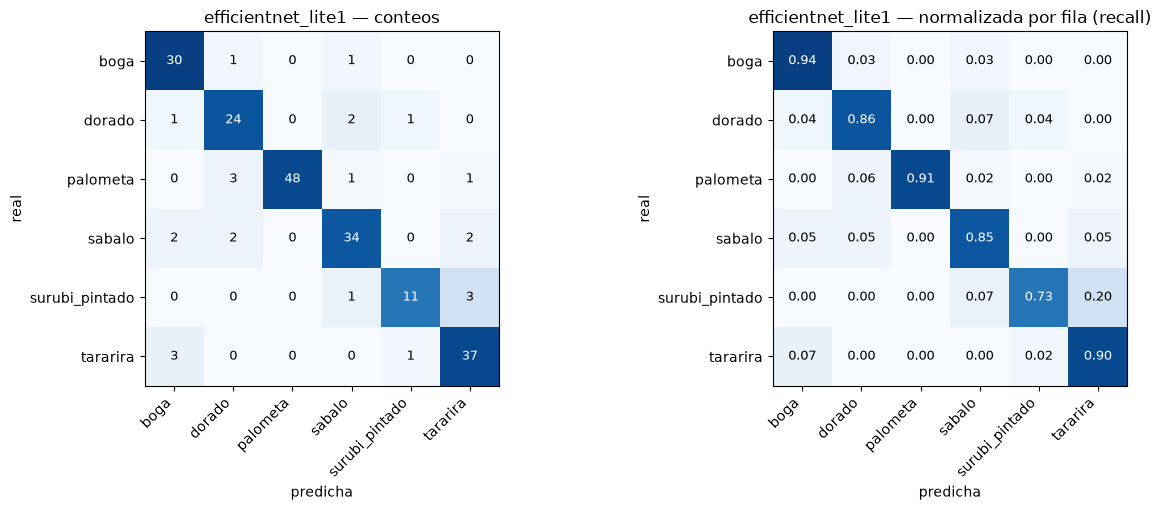

In [14]:
_ = run_experiment("efficientnet_lite1")

### EfficientNet B0 (torchvision)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\juanm/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:01<00:00, 14.0MB/s]


efficientnet_b0: 4.02 M parámetros (4.02 M entrenables)


[efficientnet_b0] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

[efficientnet_b0] época  1/40 | train loss 1.7412 mAP 0.3311 | val loss 1.3942 mAP 0.7423 acc 0.6753 | 11.7s | ETA máx 7.6 min  *mejor*


...

[efficientnet_b0] época 24/40:   0%|          | 0/28 [00:00<?, ?it/s]

[efficientnet_b0] época 24/40 | train loss 0.5334 mAP 0.9996 | val loss 0.6455 mAP 0.9880 acc 0.9588 | 11.2s | ETA máx 3.0 min


[efficientnet_b0] época 25/40:   0%|          | 0/28 [00:00<?, ?it/s]

[efficientnet_b0] época 25/40 | train loss 0.5206 mAP 0.9998 | val loss 0.6380 mAP 0.9918 acc 0.9588 | 11.2s | ETA máx 2.8 min
[efficientnet_b0] early stopping: 8 épocas sin mejorar val mAP
[efficientnet_b0] fin: 4.7 min, mejor época 17 (val mAP 0.9921)
[efficientnet_b0] TEST  test_loss=0.6778  test_acc=0.9330  test_balanced_acc=0.9187  test_precision_macro=0.9370  test_recall_macro=0.9187  test_f1_macro=0.9268  test_f1_weighted=0.9328  test_mAP=0.9751  test_top2_acc=0.9952  test_kappa=0.9175
[efficientnet_b0] 0.77 GFLOPs | 16.2 MB | GPU 13.31 ms/img (518 img/s @bs32) | CPU 21.0 ms/img


,precision,recall,f1,AP,support
boga,0.968,0.938,0.952,0.981,32
dorado,0.889,0.857,0.873,0.974,28
palometa,0.981,1.000,0.991,1.000,53
sabalo,0.854,0.875,0.864,0.948,40
surubi_pintado,1.000,0.867,0.929,0.975,15
tararira,0.930,0.976,0.952,0.973,41


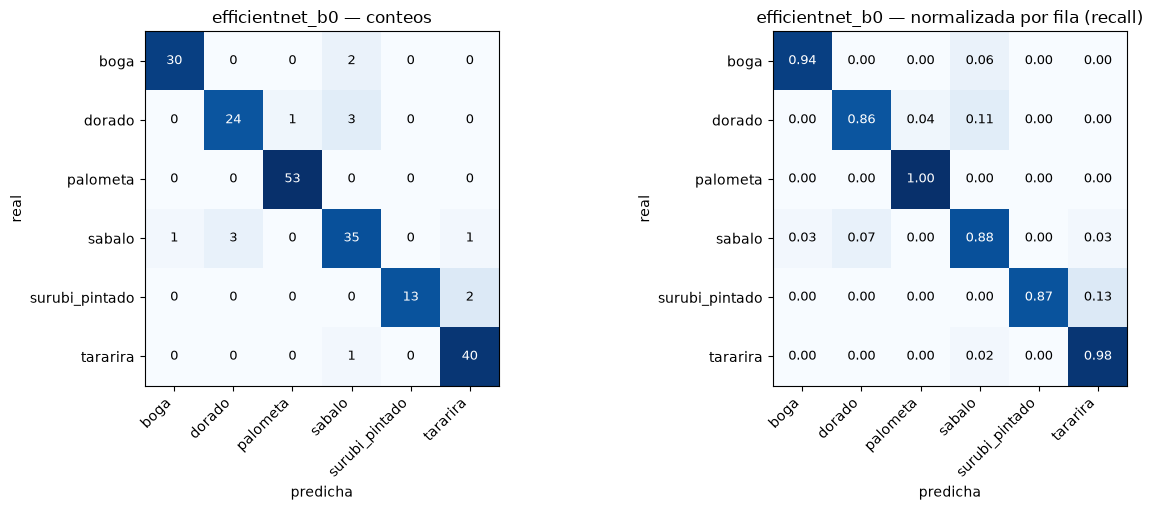

In [15]:
_ = run_experiment("efficientnet_b0")

### ConvNeXt Pico (timm)

model.safetensors: reconstructing file:   0%|          |  0.00B / 36.2MB            

model.safetensors: downloading bytes:           |  0.00B            

convnext_pico: 8.54 M parámetros (8.54 M entrenables)


c:\Users\juanm\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\juanm\.cache\huggingface\hub\models--timm--convnext_pico.d1_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[convnext_pico] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

...

[convnext_pico] época 12/40:   0%|          | 0/28 [00:00<?, ?it/s]

[convnext_pico] época 12/40 | train loss 0.5756 mAP 0.9909 | val loss 0.7210 mAP 0.9750 acc 0.9278 | 23.1s | ETA máx 10.9 min


[convnext_pico] época 13/40:   0%|          | 0/28 [00:00<?, ?it/s]

[convnext_pico] época 13/40 | train loss 0.5705 mAP 0.9904 | val loss 0.6928 mAP 0.9740 acc 0.9278 | 23.0s | ETA máx 10.5 min
[convnext_pico] early stopping: 8 épocas sin mejorar val mAP
[convnext_pico] fin: 5.1 min, mejor época 5 (val mAP 0.9966)
[convnext_pico] TEST  test_loss=0.7018  test_acc=0.9187  test_balanced_acc=0.9074  test_precision_macro=0.8963  test_recall_macro=0.9074  test_f1_macro=0.8988  test_f1_weighted=0.9207  test_mAP=0.9714  test_top2_acc=0.9904  test_kappa=0.9003
[convnext_pico] 2.73 GFLOPs | 34.1 MB | GPU 5.17 ms/img (346 img/s @bs32) | CPU 20.3 ms/img


,precision,recall,f1,AP,support
boga,0.967,0.906,0.935,0.976,32
dorado,0.962,0.893,0.926,0.961,28
palometa,1.000,1.000,1.000,1.000,53
sabalo,0.902,0.925,0.914,0.966,40
surubi_pintado,0.650,0.867,0.743,0.938,15
tararira,0.897,0.854,0.875,0.987,41


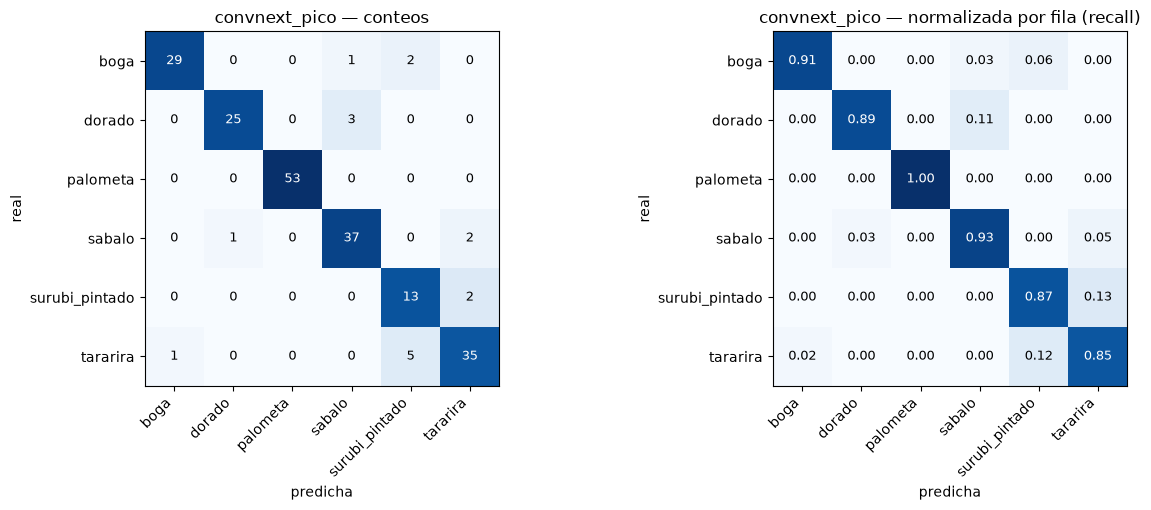

In [16]:
_ = run_experiment("convnext_pico")

### ConvNeXt Nano (timm, preentrenado in12k → in1k)

model.safetensors: reconstructing file:   0%|          |  0.00B / 62.4MB            

model.safetensors: downloading bytes:           |  0.00B            

convnext_nano: 14.96 M parámetros (14.96 M entrenables)


c:\Users\juanm\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\juanm\.cache\huggingface\hub\models--timm--convnext_nano.in12k_ft_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[convnext_nano] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

...

[convnext_nano] época 26/40:   0%|          | 0/28 [00:00<?, ?it/s]

[convnext_nano] época 26/40 | train loss 0.5036 mAP 0.9999 | val loss 0.6103 mAP 0.9892 acc 0.9742 | 36.7s | ETA máx 8.5 min


[convnext_nano] época 27/40:   0%|          | 0/28 [00:00<?, ?it/s]

[convnext_nano] época 27/40 | train loss 0.5064 mAP 0.9993 | val loss 0.6102 mAP 0.9877 acc 0.9691 | 36.9s | ETA máx 7.9 min
[convnext_nano] early stopping: 8 épocas sin mejorar val mAP
[convnext_nano] fin: 16.5 min, mejor época 19 (val mAP 0.9979)
[convnext_nano] TEST  test_loss=0.7187  test_acc=0.9139  test_balanced_acc=0.9036  test_precision_macro=0.8975  test_recall_macro=0.9036  test_f1_macro=0.8990  test_f1_weighted=0.9135  test_mAP=0.9595  test_top2_acc=0.9761  test_kappa=0.8943
[convnext_nano] 4.89 GFLOPs | 59.8 MB | GPU 9.02 ms/img (200 img/s @bs32) | CPU 32.9 ms/img


,precision,recall,f1,AP,support
boga,0.933,0.875,0.903,0.919,32
dorado,0.839,0.929,0.881,0.974,28
palometa,1.000,1.000,1.000,1.000,53
sabalo,0.914,0.800,0.853,0.939,40
surubi_pintado,0.812,0.867,0.839,0.946,15
tararira,0.886,0.951,0.918,0.979,41


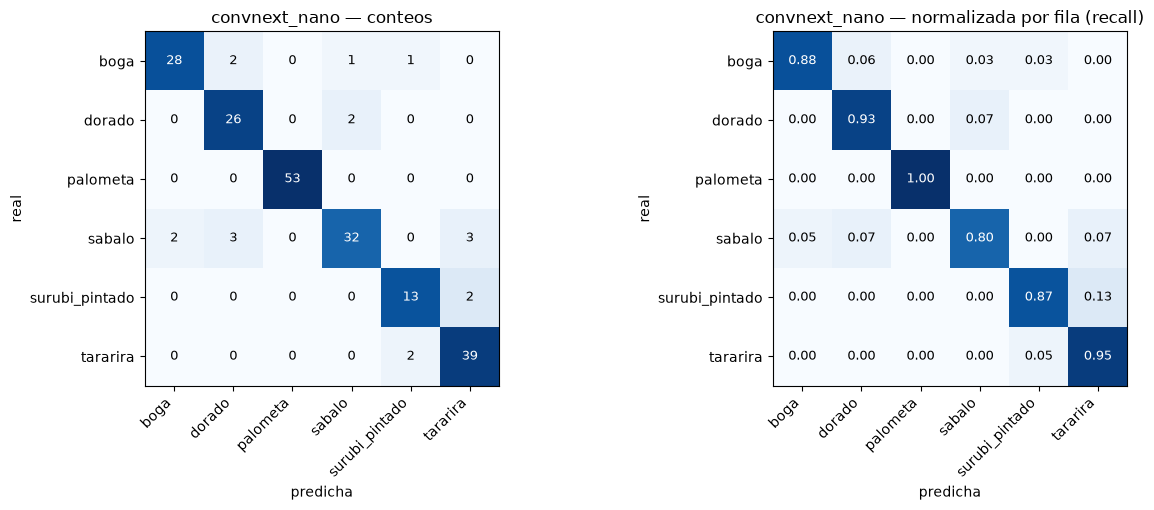

In [17]:
_ = run_experiment("convnext_nano")

### ConvNeXt Tiny (torchvision)

In [18]:
_ = run_experiment("convnext_tiny", batch=16)  # 28 M parámetros: batch 16 para no pasarse de 4 GB de VRAM

convnext_tiny: 27.82 M parámetros (27.82 M entrenables)


[convnext_tiny] época 1/40:   0%|          | 0/57 [00:00<?, ?it/s]

[convnext_tiny] época  1/40 | train loss 1.2561 mAP 0.7233 | val loss 0.9974 mAP 0.9637 acc 0.7732 | 84.2s | ETA máx 54.8 min  *mejor*


[convnext_tiny] época 2/40:   0%|          | 0/57 [00:00<?, ?it/s]

[convnext_tiny] época  2/40 | train loss 0.7765 mAP 0.9239 | val loss 0.6990 mAP 0.9741 acc 0.9330 | 83.3s | ETA máx 53.1 min  *mejor*


...

[convnext_tiny] época 13/40 | train loss 0.5375 mAP 0.9942 | val loss 0.6078 mAP 0.9977 acc 0.9742 | 86.2s | ETA máx 38.9 min  *mejor*


[convnext_tiny] época 14/40:   0%|          | 0/57 [00:00<?, ?it/s]

[convnext_tiny] época 14/40 | train loss 0.5660 mAP 0.9912 | val loss 0.7110 mAP 0.9839 acc 0.9227 | 87.0s | ETA máx 37.5 min


[convnext_tiny] época 15/40:   0%|          | 0/57 [00:00<?, ?it/s]

KeyboardInterrupt: 

### ShuffleNetV2 0.5x (torchvision)

shufflenet_v2_x0_5: 0.35 M parámetros (0.35 M entrenables)


[shufflenet_v2_x0_5] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

[shufflenet_v2_x0_5] época  1/40 | train loss 1.8310 mAP 0.2330 | val loss 1.8467 mAP 0.4633 acc 0.4588 | 5.7s | ETA máx 3.7 min  *mejor*


[shufflenet_v2_x0_5] época 2/40:   0%|          | 0/28 [00:00<?, ?it/s]

[shufflenet_v2_x0_5] época  2/40 | train loss 1.8089 mAP 0.4496 | val loss 1.7993 mAP 0.5987 acc 0.4536 | 4.8s | ETA máx 3.3 min  *mejor*


...

[shufflenet_v2_x0_5] época 29/40:   0%|          | 0/28 [00:00<?, ?it/s]

[shufflenet_v2_x0_5] época 29/40 | train loss 0.7149 mAP 0.9621 | val loss 0.7776 mAP 0.9578 acc 0.8969 | 4.8s | ETA máx 0.9 min


[shufflenet_v2_x0_5] época 30/40:   0%|          | 0/28 [00:00<?, ?it/s]

[shufflenet_v2_x0_5] época 30/40 | train loss 0.7622 mAP 0.9446 | val loss 0.7821 mAP 0.9584 acc 0.8969 | 4.7s | ETA máx 0.8 min
[shufflenet_v2_x0_5] early stopping: 8 épocas sin mejorar val mAP
[shufflenet_v2_x0_5] fin: 2.5 min, mejor época 22 (val mAP 0.9623)
[shufflenet_v2_x0_5] TEST  test_loss=0.8814  test_acc=0.8182  test_balanced_acc=0.8057  test_precision_macro=0.7939  test_recall_macro=0.8057  test_f1_macro=0.7963  test_f1_weighted=0.8206  test_mAP=0.8940  test_top2_acc=0.9474  test_kappa=0.7776
[shufflenet_v2_x0_5] 0.08 GFLOPs | 1.4 MB | GPU 8.53 ms/img (3077 img/s @bs32) | CPU 10.1 ms/img


,precision,recall,f1,AP,support
boga,0.750,0.844,0.794,0.878,32
dorado,0.923,0.857,0.889,0.917,28
palometa,0.962,0.943,0.952,0.991,53
sabalo,0.829,0.725,0.773,0.870,40
surubi_pintado,0.550,0.733,0.629,0.838,15
tararira,0.750,0.732,0.741,0.871,41


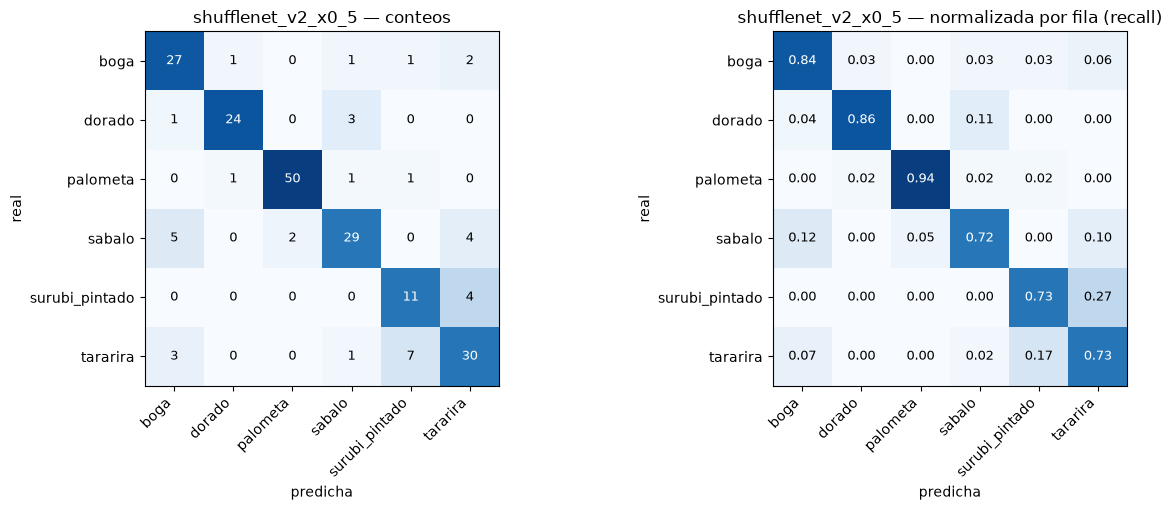

In [19]:
_ = run_experiment("shufflenet_v2_x0_5")

### ShuffleNetV2 1.0x (torchvision)

Downloading: "https://download.pytorch.org/models/shufflenetv2_x1-5666bf0f80.pth" to C:\Users\juanm/.cache\torch\hub\checkpoints\shufflenetv2_x1-5666bf0f80.pth


100%|██████████| 8.79M/8.79M [00:01<00:00, 7.73MB/s]

shufflenet_v2_x1_0: 1.26 M parámetros (1.26 M entrenables)


[shufflenet_v2_x1_0] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

[shufflenet_v2_x1_0] época  1/40 | train loss 1.8275 mAP 0.3084 | val loss 1.8314 mAP 0.6686 acc 0.4485 | 6.8s | ETA máx 4.5 min  *mejor*


...

[shufflenet_v2_x1_0] época 30/40:   0%|          | 0/28 [00:00<?, ?it/s]

[shufflenet_v2_x1_0] época 30/40 | train loss 0.5831 mAP 0.9944 | val loss 0.6630 mAP 0.9865 acc 0.9588 | 5.3s | ETA máx 0.9 min


[shufflenet_v2_x1_0] época 31/40:   0%|          | 0/28 [00:00<?, ?it/s]

[shufflenet_v2_x1_0] época 31/40 | train loss 0.5881 mAP 0.9922 | val loss 0.6724 mAP 0.9850 acc 0.9536 | 5.3s | ETA máx 0.8 min
[shufflenet_v2_x1_0] early stopping: 8 épocas sin mejorar val mAP
[shufflenet_v2_x1_0] fin: 2.8 min, mejor época 23 (val mAP 0.9920)
[shufflenet_v2_x1_0] TEST  test_loss=0.7967  test_acc=0.8852  test_balanced_acc=0.8734  test_precision_macro=0.8733  test_recall_macro=0.8734  test_f1_macro=0.8729  test_f1_weighted=0.8847  test_mAP=0.9149  test_top2_acc=0.9569  test_kappa=0.8589
[shufflenet_v2_x1_0] 0.29 GFLOPs | 5.1 MB | GPU 8.56 ms/img (1557 img/s @bs32) | CPU 15.5 ms/img


,precision,recall,f1,AP,support
boga,0.882,0.938,0.909,0.966,32
dorado,0.889,0.857,0.873,0.919,28
palometa,0.943,0.943,0.943,0.937,53
sabalo,0.865,0.800,0.831,0.829,40
surubi_pintado,0.800,0.800,0.800,0.883,15
tararira,0.860,0.902,0.881,0.955,41


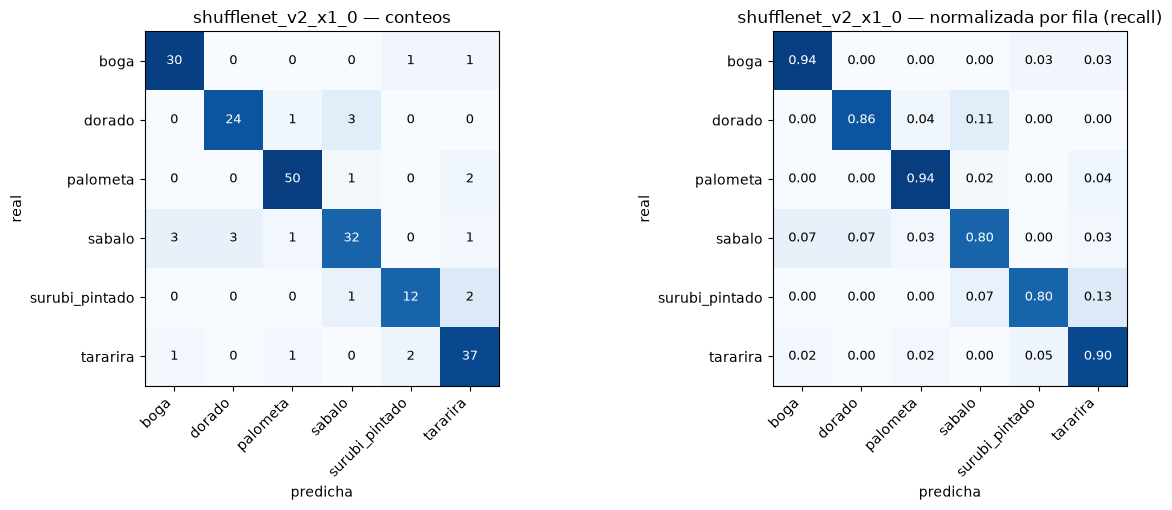

In [20]:
_ = run_experiment("shufflenet_v2_x1_0")

### ResNet18 (torchvision)

resnet18: 11.18 M parámetros (11.18 M entrenables)


[resnet18] época 1/40:   0%|          | 0/28 [00:00<?, ?it/s]

[resnet18] época  1/40 | train loss 1.4554 mAP 0.5455 | val loss 1.0576 mAP 0.8921 acc 0.8299 | 15.3s | ETA máx 10.0 min  *mejor*


[resnet18] época 2/40:   0%|          | 0/28 [00:00<?, ?it/s]

[resnet18] época  2/40 | train loss 0.9570 mAP 0.8469 | val loss 1.0309 mAP 0.8817 acc 0.7526 | 16.2s | ETA máx 10.0 min


...

[resnet18] época 39/40:   0%|          | 0/28 [00:00<?, ?it/s]

[resnet18] época 39/40 | train loss 0.5325 mAP 0.9998 | val loss 0.6290 mAP 0.9918 acc 0.9742 | 15.0s | ETA máx 0.3 min


[resnet18] época 40/40:   0%|          | 0/28 [00:00<?, ?it/s]

[resnet18] época 40/40 | train loss 0.5383 mAP 0.9995 | val loss 0.6281 mAP 0.9926 acc 0.9742 | 15.1s | ETA máx 0.0 min
[resnet18] early stopping: 8 épocas sin mejorar val mAP
[resnet18] fin: 10.7 min, mejor época 32 (val mAP 0.9943)
[resnet18] TEST  test_loss=0.6500  test_acc=0.9426  test_balanced_acc=0.9386  test_precision_macro=0.9335  test_recall_macro=0.9386  test_f1_macro=0.9352  test_f1_weighted=0.9423  test_mAP=0.9861  test_top2_acc=0.9904  test_kappa=0.9295
[resnet18] 3.63 GFLOPs | 44.8 MB | GPU 3.65 ms/img (667 img/s @bs32) | CPU 21.9 ms/img


,precision,recall,f1,AP,support
boga,0.912,0.969,0.939,0.993,32
dorado,0.963,0.929,0.945,0.990,28
palometa,1.000,1.000,1.000,1.000,53
sabalo,0.944,0.850,0.895,0.986,40
surubi_pintado,0.875,0.933,0.903,0.965,15
tararira,0.907,0.951,0.929,0.983,41


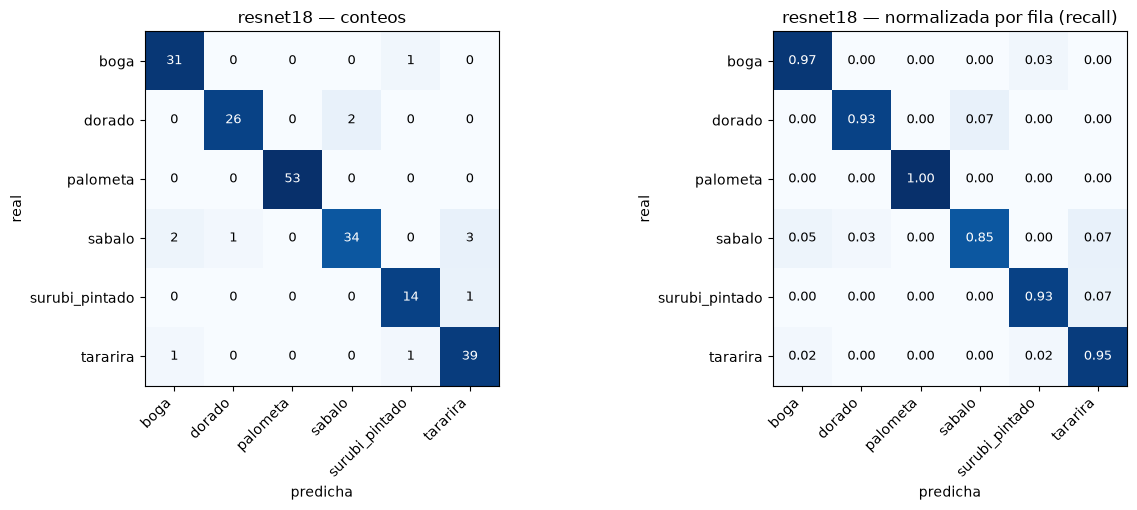

In [21]:
_ = run_experiment("resnet18")

## 5. Comparación NO TENER EN CUENTA CONVNEXT-TINY

Tabla ordenada por test mAP. `pareto` marca los modelos que ningún otro supera a la vez en test mAP **y** latencia CPU (los candidatos razonables para correr en el celular/edge).

In [22]:
for name in MODELS:              # carga los que falten si se corrió solo esta sección
    if name not in ALL_RESULTS and (RUNS / name / "results.json").exists():
        ALL_RESULTS[name] = dict(summary=json.loads((RUNS / name / "results.json").read_text()),
                                 history=pd.read_csv(RUNS / name / "history.csv"),
                                 per_class=pd.read_csv(RUNS / name / "per_class.csv", index_col=0),
                                 confusion=np.load(RUNS / name / "confusion.npy"),
                                 preds=pd.read_csv(RUNS / name / "test_preds.csv"))

summary = pd.DataFrame([r["summary"] for r in ALL_RESULTS.values()]).set_index("model")
summary["pareto"] = [not ((summary.test_mAP >= r.test_mAP) & (summary.latency_cpu_ms <= r.latency_cpu_ms) &
                          ((summary.test_mAP > r.test_mAP) | (summary.latency_cpu_ms < r.latency_cpu_ms))).any()
                     for r in summary.itertuples()]
summary["overfit_gap_mAP"] = summary.train_mAP - summary.val_mAP
summary.to_csv(RUNS / "comparison.csv")

COLS = ["library", "params_M", "GFLOPs", "size_MB", "latency_cpu_ms", "latency_gpu_ms", "throughput_gpu_img_s",
        "peak_gpu_mem_GB", "epochs_run", "best_epoch", "sec_per_epoch", "train_time_min",
        "val_mAP", "overfit_gap_mAP", "test_mAP", "test_acc", "test_balanced_acc", "test_f1_macro",
        "test_top2_acc", "test_kappa", "worst_class", "worst_class_f1", "pareto"]
table = summary[COLS].sort_values("test_mAP", ascending=False)
(table.style
      .format(precision=3)
      .format("{:.2f}", subset=["params_M", "GFLOPs", "size_MB", "latency_cpu_ms", "latency_gpu_ms", "peak_gpu_mem_GB", "sec_per_epoch", "train_time_min"])
      .format("{:.0f}", subset=["throughput_gpu_img_s"])
      .background_gradient(cmap="Blues", subset=["val_mAP", "test_mAP", "test_acc", "test_balanced_acc", "test_f1_macro"])
      .background_gradient(cmap="Greys", subset=["params_M", "GFLOPs", "latency_cpu_ms"]))

,library,params_M,GFLOPs,size_MB,latency_cpu_ms,latency_gpu_ms,throughput_gpu_img_s,peak_gpu_mem_GB,epochs_run,best_epoch,sec_per_epoch,train_time_min,val_mAP,overfit_gap_mAP,test_mAP,test_acc,test_balanced_acc,test_f1_macro,test_top2_acc,test_kappa,worst_class,worst_class_f1,pareto
model,,,,,,,,,,,,,,,,,,,,,,,
resnet18,torchvision,11.18,3.63,44.76,21.93,3.65,667,1.28,40,32,16.00,10.67,0.994,0.005,0.986,0.943,0.939,0.935,0.990,0.930,sabalo,0.895,True
efficientnet_b0,torchvision,4.02,0.77,16.23,21.02,13.31,518,1.63,25,17,11.15,4.65,0.992,0.006,0.975,0.933,0.919,0.927,0.995,0.918,sabalo,0.864,True
convnext_pico,timm,8.54,2.73,34.14,20.34,5.17,346,1.24,13,5,23.40,5.07,0.997,-0.018,0.971,0.919,0.907,0.899,0.990,0.900,surubi_pintado,0.743,True
mobilenet_v3_large,torchvision,4.21,0.43,16.94,15.27,8.85,873,0.92,22,14,8.56,3.14,0.993,0.006,0.970,0.943,0.930,0.935,0.995,0.929,sabalo,0.889,True
convnext_nano,timm,14.96,4.89,59.83,32.91,9.02,200,1.75,27,19,36.59,16.47,0.998,0.000,0.960,0.914,0.904,0.899,0.976,0.894,surubi_pintado,0.839,False
efficientnet_lite0,timm,3.38,0.77,13.68,18.52,9.74,525,1.48,25,17,10.78,4.50,0.966,0.026,0.958,0.914,0.912,0.898,0.962,0.895,surubi_pintado,0.765,False
efficientnet_lite1,timm,4.14,1.00,16.79,21.83,9.92,408,1.87,25,17,13.06,5.45,0.960,0.037,0.941,0.880,0.864,0.865,0.962,0.853,surubi_pintado,0.786,False
shufflenet_v2_x1_0,torchvision,1.26,0.29,5.10,15.51,8.56,1557,1.06,31,23,5.41,2.81,0.992,-0.006,0.915,0.885,0.873,0.873,0.957,0.859,surubi_pintado,0.800,False
mobilenet_v3_small,torchvision,1.52,0.11,6.14,8.66,7.99,2436,0.41,14,6,5.11,1.20,0.986,-0.045,0.902,0.847,0.823,0.817,0.957,0.812,surubi_pintado,0.667,True


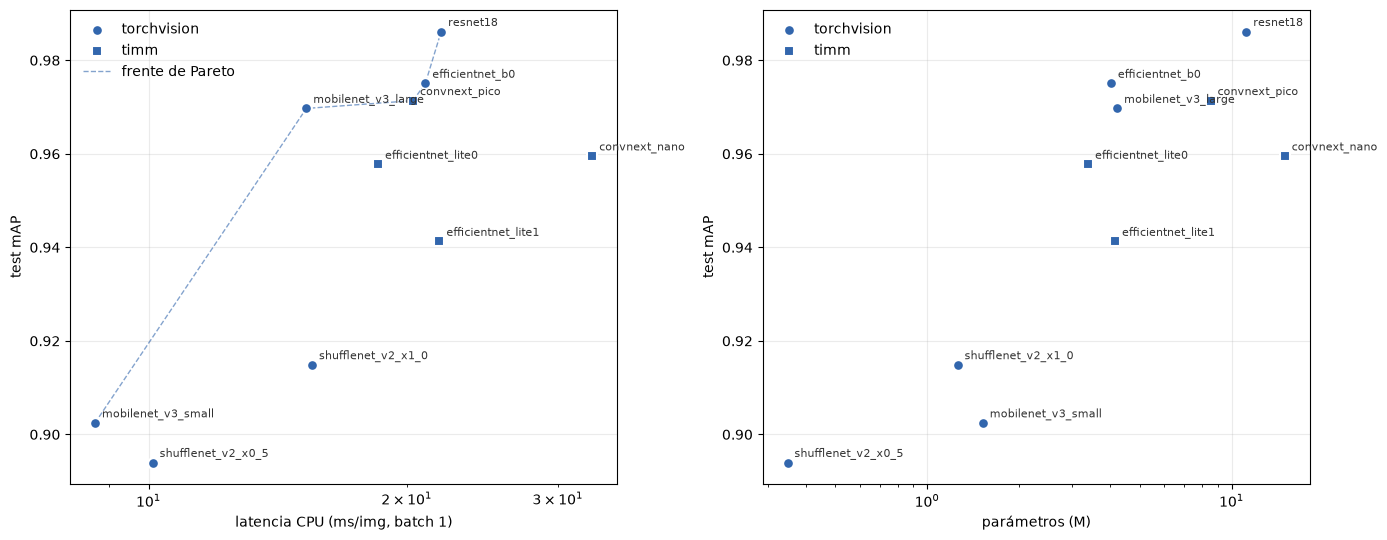

In [23]:
# Precisión vs costo: test mAP contra latencia CPU y contra parámetros (etiqueta directa en cada punto)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, xcol, xlabel in [(axes[0], "latency_cpu_ms", "latencia CPU (ms/img, batch 1)"), (axes[1], "params_M", "parámetros (M)")]:
    for lib, marker in [("torchvision", "o"), ("timm", "s")]:
        d = summary[summary.library == lib]
        ax.scatter(d[xcol], d.test_mAP, s=60, marker=marker, color="#3266ad", edgecolor="white", linewidth=1.5, label=lib, zorder=3)
    front = summary[summary.pareto].sort_values(xcol)
    if xcol == "latency_cpu_ms":
        ax.plot(front[xcol], front.test_mAP, color="#3266ad", lw=1, ls="--", alpha=0.6, label="frente de Pareto")
    for name, r in summary.iterrows():
        ax.annotate(name, (r[xcol], r.test_mAP), xytext=(5, 4), textcoords="offset points", fontsize=8, color="#333")
    ax.set_xscale("log"); ax.set_xlabel(xlabel); ax.set_ylabel("test mAP"); ax.grid(alpha=0.25); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

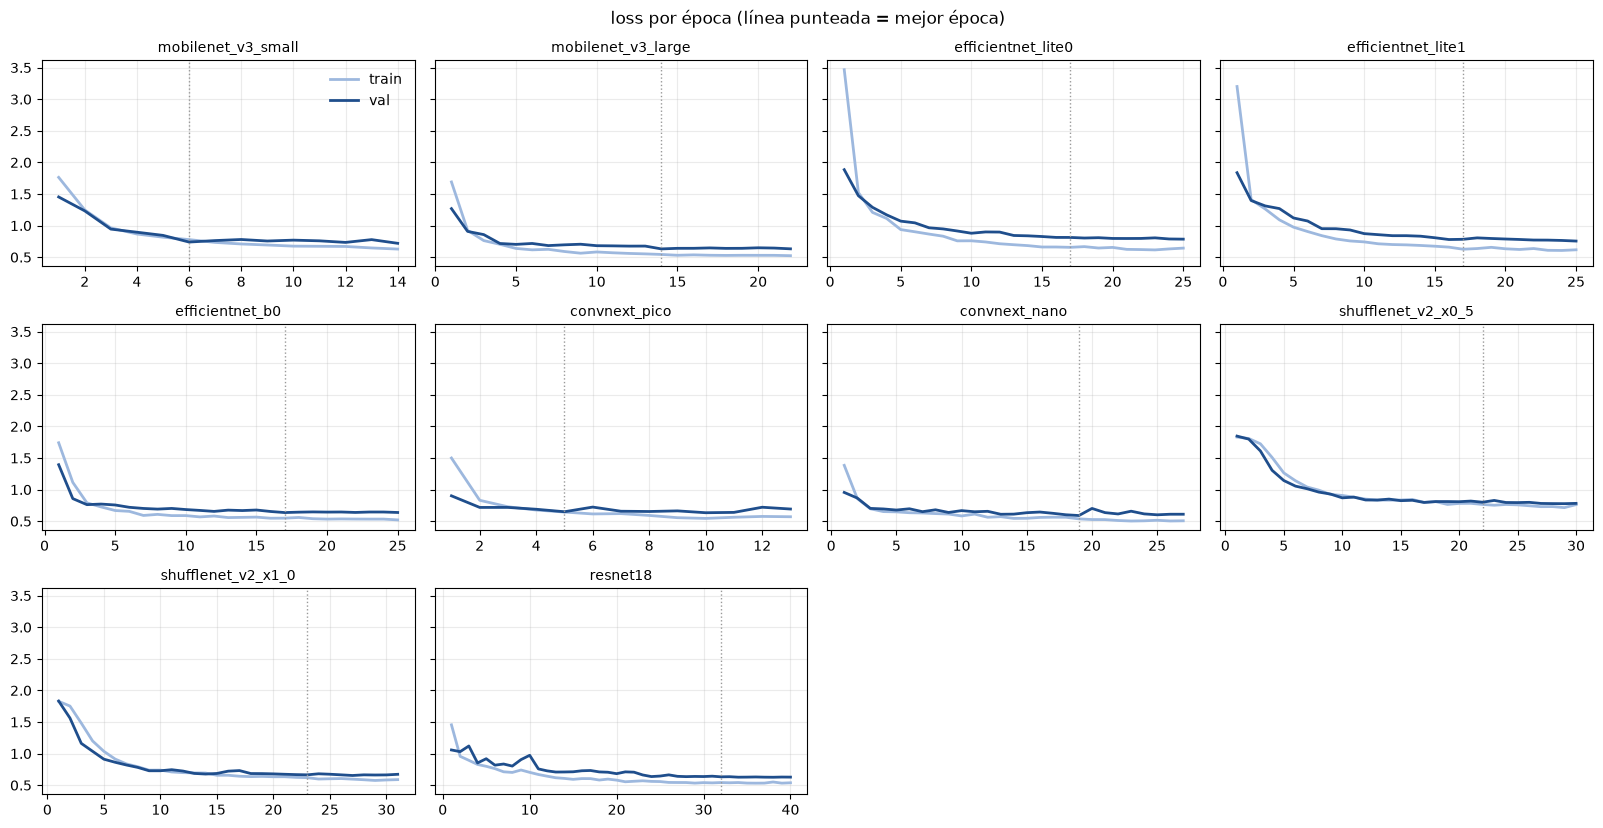

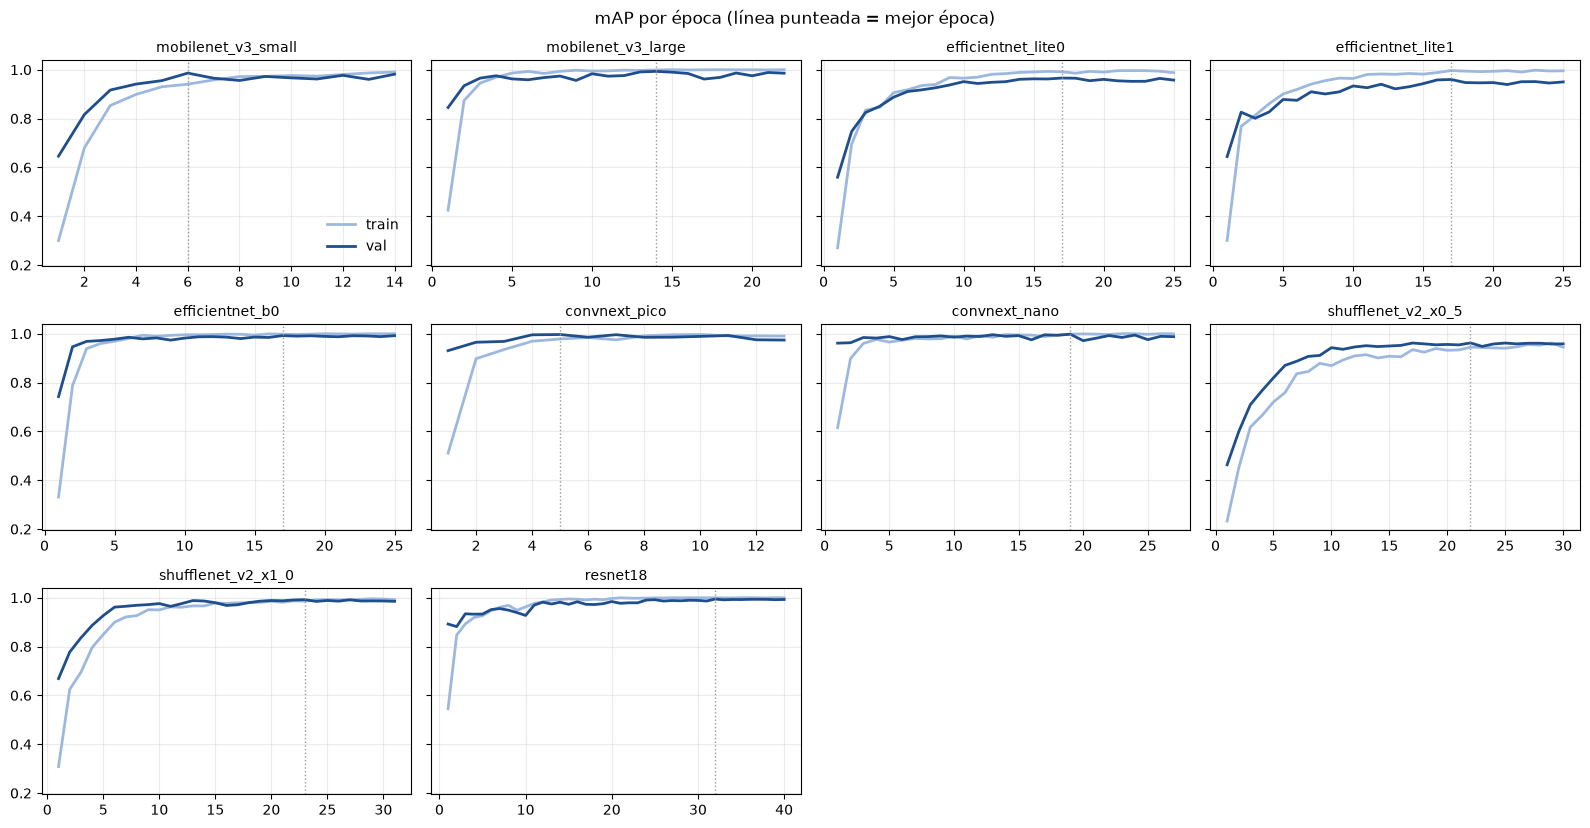

In [24]:
# Curvas de entrenamiento (small multiples): loss y mAP de train/val por época
names = list(ALL_RESULTS)
ncol = 4
nrow = math.ceil(len(names) / ncol)
for metric in ["loss", "mAP"]:
    fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.8 * nrow), sharey=True, squeeze=False)
    for ax, name in zip(axes.flat, names):
        h = ALL_RESULTS[name]["history"]
        ax.plot(h.epoch, h[f"train_{metric}"], lw=2, color="#9db8de", label="train")
        ax.plot(h.epoch, h[f"val_{metric}"], lw=2, color="#1f4e8c", label="val")
        ax.axvline(ALL_RESULTS[name]["summary"]["best_epoch"], color="#999", lw=1, ls=":")
        ax.set_title(name, fontsize=10); ax.grid(alpha=0.25)
    for ax in axes.flat[len(names):]:
        ax.axis("off")
    axes.flat[0].legend(frameon=False)
    fig.suptitle(f"{metric} por época (línea punteada = mejor época)")
    plt.tight_layout(); plt.show()

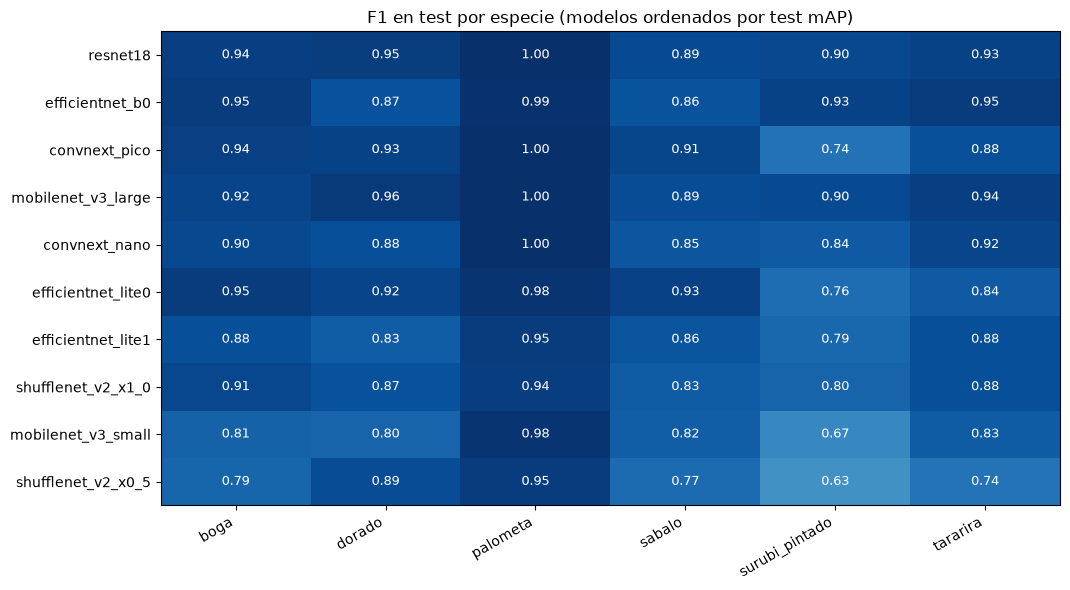

In [25]:
# F1 por especie y modelo: qué especies son difíciles para todos y cuáles dependen del modelo
f1_table = pd.DataFrame({n: r["per_class"]["f1"] for n, r in ALL_RESULTS.items()}).T.loc[table.index]
fig, ax = plt.subplots(figsize=(1.3 * NUM_CLASSES + 3, 0.45 * len(f1_table) + 1.5))
ax.imshow(f1_table.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(f1_table.shape[0]):
    for j in range(f1_table.shape[1]):
        v = f1_table.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 else "black")
ax.set_xticks(range(NUM_CLASSES), f1_table.columns, rotation=30, ha="right")
ax.set_yticks(range(len(f1_table)), f1_table.index)
ax.set_title("F1 en test por especie (modelos ordenados por test mAP)")
plt.tight_layout(); plt.show()

## 6. Errores del mejor modelo

Recortes de test mal clasificados por el modelo con mayor test mAP, ordenados por confianza (los errores con alta confianza suelen ser problemas de etiqueta o especies realmente parecidas).

resnet18: 12 errores de 209


y_pred,boga,dorado,sabalo,surubi_pintado,tararira
y_true,,,,,
boga,0,0,0,1,0
dorado,0,0,2,0,0
sabalo,2,1,0,0,3
surubi_pintado,0,0,0,0,1
tararira,1,0,0,1,0


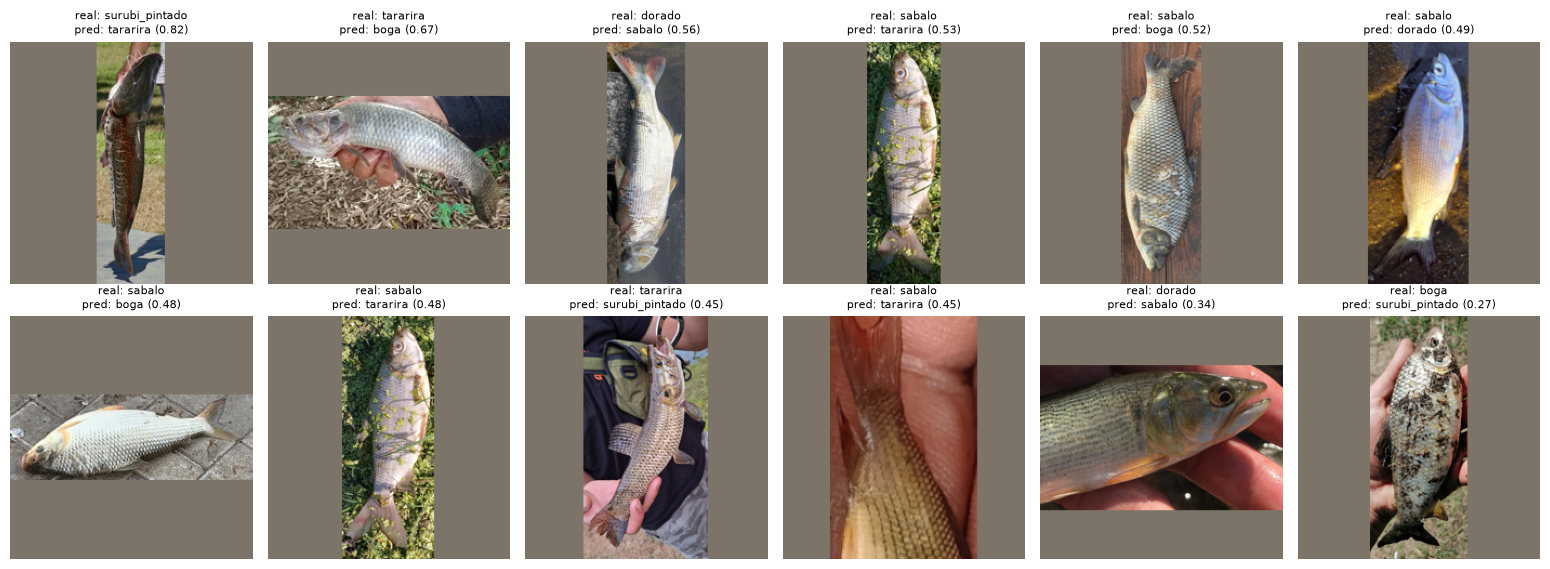

In [26]:
best_name = table.index[0]
errs = ALL_RESULTS[best_name]["preds"].query("y_true != y_pred").sort_values("conf", ascending=False)
print(f"{best_name}: {len(errs)} errores de {len(ALL_RESULTS[best_name]['preds'])}")
display(pd.crosstab(errs.y_true, errs.y_pred))
show = errs.head(24)
if len(show):
    ncol = 6
    fig, axes = plt.subplots(math.ceil(len(show) / ncol), ncol, figsize=(2.6 * ncol, 2.9 * math.ceil(len(show) / ncol)), squeeze=False)
    for ax, r in zip(axes.flat, show.itertuples()):
        ax.imshow(letterbox(Image.open(CROPS / r.crop).convert("RGB")))
        ax.set_title(f"real: {r.y_true}\npred: {r.y_pred} ({r.conf:.2f})", fontsize=8)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout(); plt.show()